# UTS Graf Sains Data
## Analisis Graf Interaksi Pengguna dan Barang pada RetailRocket

### Tujuan
Notebook ini menganalisis data interaksi pengguna dengan barang menggunakan dataset RetailRocket. Analisis meliputi pemilihan periode data, pembentukan graf pada Neo4j, representasi interaksi dalam bentuk Vector Space Model (VSM), pengukuran kemiripan antar-pengguna menggunakan cosine similarity, serta rekomendasi barang dengan pendekatan K-Nearest Neighbors (KNN).

### Alur pengerjaan
1. Persiapan lingkungan Python dan koneksi Neo4j.
2. Eksplorasi dan pemilihan periode data.
3. Pembersihan serta penyimpanan data berdasarkan periode.
4. Pembentukan graf interaksi di Neo4j.
5. Pembentukan VSM Visitor dan VSM Item.
6. Visualisasi dan perbandingan representasi graf.
7. Perhitungan cosine similarity.
8. Rekomendasi barang menggunakan KNN dan evaluasi Hit@5 serta NDCG@5.

### 1. Persiapan Lingkungan dan Koneksi Neo4j

In [1]:
import sys

print("Lokasi Python:", sys.executable)
print("Versi Python:", sys.version)

Lokasi Python: c:\Users\USER\uts-graf-sains-data\.venv\Scripts\python.exe
Versi Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [1]:
%pip install neo4j

  Using cached pytz-2026.5-py2.py3-none-any.whl.metadata (22 kB)
Using cached pytz-2026.5-py2.py3-none-any.whl (506 kB)

   ---------------------------------------- 0/2 [pytz]
   ---------------------------------------- 0/2 [pytz]
   ---------------------------------------- 0/2 [pytz]
   ---------------------------------------- 0/2 [pytz]
   ---------------------------------------- 0/2 [pytz]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 1/2 [neo4j]
   -------------------- ------------------- 

In [3]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()
print("Koneksi Python ke Neo4j berhasil!")

Koneksi Python ke Neo4j berhasil!


In [72]:
with driver.session(database="neo4j") as session:
    result = session.run("RETURN 1 AS tes_koneksi")
    print(result.single()["tes_koneksi"])

1


### 2. Eksplorasi Data dan Pemilihan Periode

In [7]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data/RetailRocket")

events = pd.read_csv(DATA_DIR / "events.csv", nrows=5)

print("Kolom events.csv:")
print(events.columns.tolist())

print("\nContoh data:")
display(events)

Kolom events.csv:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Contoh data:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [8]:
import pandas as pd

tanggal_min = None
tanggal_max = None

for chunk in pd.read_csv(
    DATA_DIR / "events.csv",
    usecols=["timestamp"],
    chunksize=500_000
):
    t = chunk["timestamp"].dropna()

    if not t.empty:
        nilai_min = t.min()
        nilai_max = t.max()

        tanggal_min = nilai_min if tanggal_min is None else min(tanggal_min, nilai_min)
        tanggal_max = nilai_max if tanggal_max is None else max(tanggal_max, nilai_max)

print("Tanggal awal:", pd.to_datetime(tanggal_min, unit="ms"))
print("Tanggal akhir:", pd.to_datetime(tanggal_max, unit="ms"))

Tanggal awal: 2015-05-03 03:00:04.384000
Tanggal akhir: 2015-09-18 02:59:47.788000


In [9]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Batas periode; tanggal akhir dibuat eksklusif agar
# seluruh kejadian pada tanggal akhir ikut masuk.
periods = {
    "P1": ("2015-05-08", "2015-06-03"),
    "P2": ("2015-08-25", "2015-09-18"),
}

# Hapus hasil lama agar tidak menggandakan baris jika dijalankan ulang
for name in periods:
    output_file = OUTPUT_DIR / f"events_{name}.csv"
    if output_file.exists():
        output_file.unlink()

counts = {"P1": 0, "P2": 0}

for chunk in pd.read_csv(DATA_DIR / "events.csv", chunksize=500_000):
    dates = pd.to_datetime(chunk["timestamp"], unit="ms")

    for name, (start, end) in periods.items():
        mask = (dates >= pd.Timestamp(start)) & (dates < pd.Timestamp(end))
        selected = chunk.loc[mask]

        if not selected.empty:
            output_file = OUTPUT_DIR / f"events_{name}.csv"
            selected.to_csv(
                output_file,
                mode="a",
                index=False,
                header=not output_file.exists()
            )
            counts[name] += len(selected)

print("Selesai memfilter data!")
print("Jumlah baris P1:", f"{counts['P1']:,}")
print("Jumlah baris P2:", f"{counts['P2']:,}")
print("Lokasi file:", OUTPUT_DIR.resolve())

Selesai memfilter data!
Jumlah baris P1: 533,588
Jumlah baris P2: 429,879
Lokasi file: C:\Users\USER\uts-graf-sains-data\data\processed


In [10]:
for name in ["P1", "P2"]:
    df = pd.read_csv(
        OUTPUT_DIR / f"events_{name}.csv",
        nrows=5
    )

    print(f"\n{name} — 5 baris pertama")
    display(df)

    print("Kolom:", df.columns.tolist())


P1 — 5 baris pertama


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

P2 — 5 baris pertama


,timestamp,visitorid,event,itemid,transactionid
0,1440468267794,298265,view,264657,NaN
1,1440466588301,248962,view,445098,NaN
2,1440468083312,514595,view,38913,NaN
3,1440468178338,664343,view,195452,NaN
4,1440470382551,1081664,view,411271,NaN


Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


In [11]:
p1 = pd.read_csv(OUTPUT_DIR / "events_P1.csv")

print("Jumlah baris P1:", len(p1))
print("\nJumlah setiap jenis event:")
print(p1["event"].value_counts())

print("\nJumlah visitor unik:", p1["visitorid"].nunique())
print("Jumlah item unik:", p1["itemid"].nunique())
print("Jumlah transaction ID unik:", p1["transactionid"].nunique())

Jumlah baris P1: 533588

Jumlah setiap jenis event:
event
view           516757
addtocart       12751
transaction      4080
Name: count, dtype: int64

Jumlah visitor unik: 280229
Jumlah item unik: 109152
Jumlah transaction ID unik: 3227


### 3. Pembentukan Graf Interaksi pada Neo4j

In [12]:
with driver.session(database="neo4j") as session:
    result = session.run("RETURN 'neo4j' AS database, 1 AS tes")
    print(result.single().data())

{'database': 'neo4j', 'tes': 1}


In [13]:
with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemid IS UNIQUE
    """).consume()

print("Constraint Visitor dan Item berhasil dibuat.")

Constraint Visitor dan Item berhasil dibuat.


In [14]:
import pandas as pd

QUERY = """
UNWIND $rows AS row
MERGE (v:Visitor {visitorid: toInteger(row.visitorid)})
MERGE (i:Item {itemid: toInteger(row.itemid)})
WITH v, i, row
FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
    CREATE (v)-[:VIEWED {timestamp: toInteger(row.timestamp)}]->(i)
)
FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
    CREATE (v)-[:ADDED_TO_CART {timestamp: toInteger(row.timestamp)}]->(i)
)
FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
    CREATE (v)-[:BOUGHT {
        timestamp: toInteger(row.timestamp),
        transactionId: toInteger(row.transactionid)
    }]->(i)
)
"""

batch_size = 5000
total = 0

for chunk in pd.read_csv(
    OUTPUT_DIR / "events_P1.csv",
    chunksize=batch_size
):
    # Ubah nilai kosong menjadi None agar bisa dikirim ke Neo4j
    chunk = chunk.astype(object).where(pd.notna(chunk), None)
    rows = chunk.to_dict("records")

    with driver.session(database="neo4j") as session:
        session.run(QUERY, rows=rows).consume()

    total += len(rows)
    print(f"Sudah diproses: {total:,} baris")

print(f"Impor P1 selesai: {total:,} baris.")

Sudah diproses: 5,000 baris
Sudah diproses: 10,000 baris
Sudah diproses: 15,000 baris
Sudah diproses: 20,000 baris
Sudah diproses: 25,000 baris
Sudah diproses: 30,000 baris
Sudah diproses: 35,000 baris
Sudah diproses: 40,000 baris
Sudah diproses: 45,000 baris
Sudah diproses: 50,000 baris
Sudah diproses: 55,000 baris
Sudah diproses: 60,000 baris
Sudah diproses: 65,000 baris
Sudah diproses: 70,000 baris
Sudah diproses: 75,000 baris
Sudah diproses: 80,000 baris
Sudah diproses: 85,000 baris
Sudah diproses: 90,000 baris
Sudah diproses: 95,000 baris
Sudah diproses: 100,000 baris
Sudah diproses: 105,000 baris
Sudah diproses: 110,000 baris
Sudah diproses: 115,000 baris
Sudah diproses: 120,000 baris
Sudah diproses: 125,000 baris
Sudah diproses: 130,000 baris
Sudah diproses: 135,000 baris
Sudah diproses: 140,000 baris
Sudah diproses: 145,000 baris
Sudah diproses: 150,000 baris
Sudah diproses: 155,000 baris
Sudah diproses: 160,000 baris
Sudah diproses: 165,000 baris
Sudah diproses: 170,000 baris


In [15]:
with driver.session(database="neo4j") as session:
    print("Jumlah node:")
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS tipe, count(n) AS jumlah
        ORDER BY tipe
    """)
    for record in result:
        print(record["tipe"], ":", f'{record["jumlah"]:,}')

    print("\nJumlah relasi:")
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS tipe, count(r) AS jumlah
        ORDER BY tipe
    """)
    for record in result:
        print(record["tipe"], ":", f'{record["jumlah"]:,}')

Jumlah node:
['Item'] : 109,152
['Visitor'] : 280,229

Jumlah relasi:
ADDED_TO_CART : 12,751
BOUGHT : 4,080
VIEWED : 516,757


Subgraf P1 dibentuk dari data interaksi RetailRocket pada periode 8 Mei 2015 sampai 2 Juni 2015. Graf terdiri dari dua tipe simpul, yaitu `Visitor` dan `Item`, serta tiga tipe relasi, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`.

Hasil query menggunakan Python API Neo4j menunjukkan terdapat 280.229 simpul `Visitor` dan 109.152 simpul `Item`, sehingga total simpul berjumlah 389.381. Sementara itu, terdapat 516.757 relasi `VIEWED`, 12.751 relasi `ADDED_TO_CART`, dan 4.080 relasi `BOUGHT`, dengan total 533.588 relasi.

Relasi `VIEWED` merupakan relasi paling dominan. Hal ini konsisten dengan distribusi event pada data P1, yang menunjukkan bahwa aktivitas melihat barang jauh lebih sering terjadi dibandingkan aktivitas menambahkan barang ke keranjang atau melakukan transaksi.

Query Cypher yang digunakan adalah `MATCH (n) RETURN labels(n) AS tipe, count(n) AS jumlah` untuk menghitung simpul berdasarkan label, dan `MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah` untuk menghitung relasi berdasarkan jenisnya.


### Visualisasi Subgraf Interaksi Pengguna di Neo4j

Visualisasi berikut menunjukkan subgraf interaksi pengguna `286616` dengan barang-barang yang terhubung melalui relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Untuk menjaga visualisasi tetap terbaca, query dibatasi hingga 50 relasi

![Graf interaksi](images/graf2.png)

### 4. Representasi Interaksi Menggunakan VSM

1. VSM Visitor
VSM Visitor menyusun data interaksi dalam matriks dengan baris sebagai pengguna dan kolom sebagai barang. Nilai matriks menunjukkan apakah atau seberapa sering seorang pengguna berinteraksi dengan barang, sesuai dengan definisi yang digunakan dalam kode.Representasi ini digunakan untuk membandingkan pola interaksi antar-pengguna. Karena sebagian besar pengguna hanya berinteraksi dengan sebagian kecil dari seluruh barang, matriks bersifat sparse. Oleh sebab itu, format sparse matrix digunakan untuk menghemat penyimpanan.

2. VSM Item
VSM Item menggunakan orientasi sebaliknya: baris merupakan barang dan kolom merupakan pengguna. Pada notebook ini, VSM Item dibentuk dengan melakukan transpose terhadap VSM Visitor. Kedua matriks merepresentasikan data interaksi yang sama, tetapi ditata untuk menjawab pertanyaan analisis yang berbeda. VSM Visitor sesuai untuk analisis kemiripan pengguna, sedangkan VSM Item dapat digunakan untuk analisis kemiripan barang.

In [19]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Gunakan data training P1
p1 = pd.read_csv(OUTPUT_DIR / "events_P1.csv")

# Berikan indeks untuk setiap Visitor dan Item
visitor_codes, visitor_ids = pd.factorize(p1["visitorid"], sort=True)
item_codes, item_ids = pd.factorize(p1["itemid"], sort=True)

# Matriks Visitor x Item berdasarkan frekuensi interaksi
VSM_user = csr_matrix(
    (
        np.ones(len(p1), dtype=np.int32),
        (visitor_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids))
)

# Jumlahkan interaksi berulang pada pasangan Visitor-Item yang sama
VSM_user.sum_duplicates()

print("VSM Visitor berhasil dibuat.")
print("Jumlah Visitor:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Shape matriks:", VSM_user.shape)
print("Jumlah nilai non-zero:", VSM_user.nnz)
print("Kepadatan matriks:", f"{VSM_user.nnz / (VSM_user.shape[0] * VSM_user.shape[1]):.6%}")

VSM Visitor berhasil dibuat.
Jumlah Visitor: 280229
Jumlah Item: 109152
Shape matriks: (280229, 109152)
Jumlah nilai non-zero: 416192
Kepadatan matriks: 0.001361%


  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl.metadata (60 kB)
Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)

   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   -----------------------

In [20]:
# VSM untuk Item: baris = Item, kolom = Visitor
VSM_item = VSM_user.transpose().tocsr()

print("VSM Item berhasil dibuat.")
print("Jumlah Item:", VSM_item.shape[0])
print("Jumlah Visitor:", VSM_item.shape[1])
print("Shape matriks:", VSM_item.shape)
print("Jumlah nilai non-zero:", VSM_item.nnz)

density_item = VSM_item.nnz / (
    VSM_item.shape[0] * VSM_item.shape[1]
)
print("Kepadatan matriks:", f"{density_item:.6%}")

VSM Item berhasil dibuat.
Jumlah Item: 109152
Jumlah Visitor: 280229
Shape matriks: (109152, 280229)
Jumlah nilai non-zero: 416192
Kepadatan matriks: 0.001361%


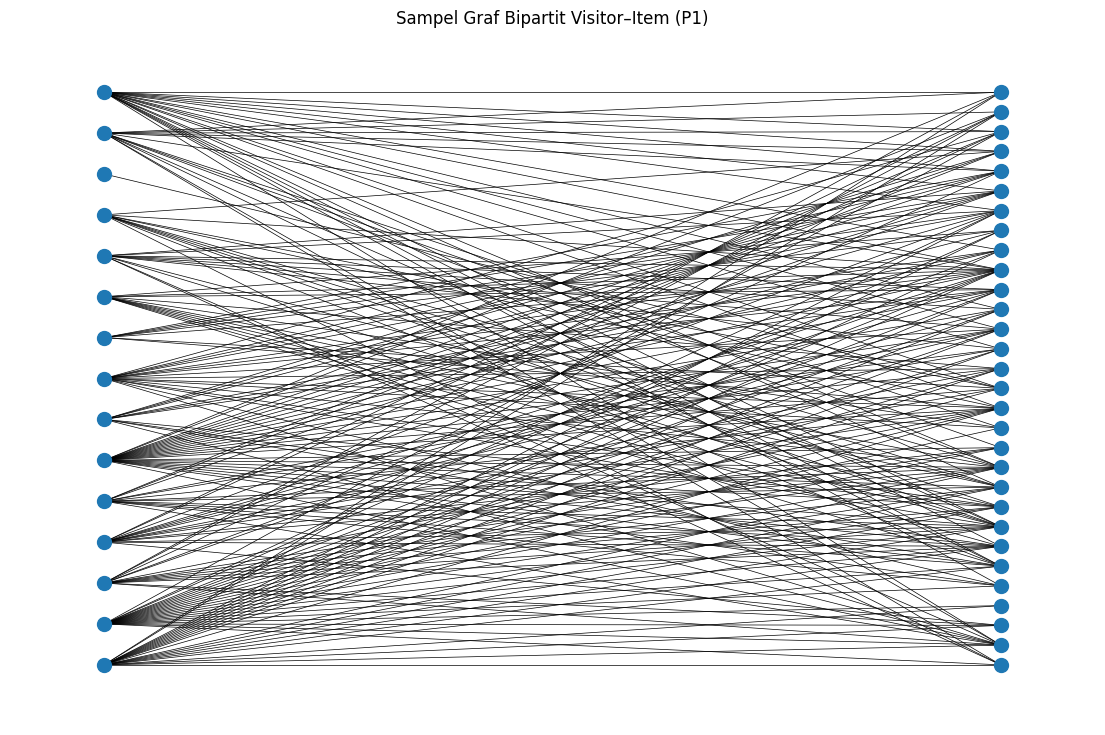

Jumlah node sampel: 45
Jumlah edge sampel: 212


In [24]:
import networkx as nx
import matplotlib.pyplot as plt

# Ambil 15 Visitor dengan interaksi terbanyak di P1
top_visitors = (
    p1["visitorid"]
    .value_counts()
    .head(15)
    .index
)

sample = p1[p1["visitorid"].isin(top_visitors)].copy()

# Batasi sampel agar visualisasi tidak terlalu padat:
# maksimal 15 Visitor dan 30 Item
top_items = sample["itemid"].value_counts().head(30).index
sample = sample[sample["itemid"].isin(top_items)]

G = nx.Graph()

for _, row in sample.iterrows():
    visitor = f"V{row['visitorid']}"
    item = f"I{row['itemid']}"

    G.add_node(visitor, bipartite="Visitor")
    G.add_node(item, bipartite="Item")
    G.add_edge(visitor, item, event=row["event"])

visitor_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == "Visitor"
]
item_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == "Item"
]

pos = nx.bipartite_layout(G, visitor_nodes)

plt.figure(figsize=(14, 9))
nx.draw_networkx(
    G,
    pos=pos,
    with_labels=False,
    node_size=100,
    width=0.5
)
plt.title("Sampel Graf Bipartit Visitor–Item (P1)")
plt.axis("off")
plt.show()

print("Jumlah node sampel:", G.number_of_nodes())
print("Jumlah edge sampel:", G.number_of_edges())

Dari hasil visualisasi di atas VSM Visitor memiliki bentuk matriks (280229, 109152), sedangkan VSM Item memiliki bentuk matriks (109152, 280229). Keduanya mempunyai 416.192 nilai non-zero dengan kepadatan sekitar 0,001361%, sehingga representasi interaksinya sama tetapi orientasinya berbeda.

Proyeksi Visitor lebih sesuai apabila tujuan analisis adalah mencari pengguna yang memiliki pola interaksi serupa untuk rekomendasi berbasis pengguna. Sebaliknya, proyeksi Item lebih sesuai apabila tujuan analisis adalah mencari barang yang memiliki pola interaksi pengunjung serupa untuk rekomendasi berbasis barang.

Kedua matriks sangat jarang (*sparse*). Oleh karena itu, penggunaan sparse matrix lebih efisien daripada matriks padat (*dense matrix*) untuk menyimpan data interaksi. Pemilihan proyeksi terbaik bergantung pada tujuan rekomendasi dan biaya komputasi, bukan hanya pada ukuran matriks.


### 5. Analisis Kemiripan Antar-Pengguna

In [31]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# Pilih Visitor yang paling banyak memiliki event di P1
visitor_counts = p1["visitorid"].value_counts()
target_visitor = visitor_counts.index[0]

# Cari posisi Visitor tersebut dalam VSM
target_idx = np.where(visitor_ids == target_visitor)[0][0]

# Hitung kemiripan Visitor acuan dengan seluruh Visitor lain
similarities = cosine_similarity(
    VSM_user[target_idx],
    VSM_user
).ravel()

# Keluarkan Visitor acuan itu sendiri
similarities[target_idx] = -1

# Ambil 5 Visitor dengan cosine similarity tertinggi
top_idx = np.argsort(similarities)[-5:][::-1]

hasil_similarity = pd.DataFrame({
    "visitor_acuan": target_visitor,
    "visitor_mirip": visitor_ids[top_idx],
    "cosine_similarity": similarities[top_idx]
})

print("Visitor acuan:", target_visitor)
print("Jumlah event Visitor acuan:", visitor_counts.loc[target_visitor])
display(hasil_similarity)

Visitor acuan: 286616
Jumlah event Visitor acuan: 2065


,visitor_acuan,visitor_mirip,cosine_similarity
0,286616,644795,0.226431
1,286616,356204,0.222974
2,286616,163561,0.198518
3,286616,350566,0.191272
4,286616,322538,0.166844


In [32]:
similarity_rows = [
    {
        "visitor_acuan": int(row.visitor_acuan),
        "visitor_mirip": int(row.visitor_mirip),
        "score": float(row.cosine_similarity)
    }
    for row in hasil_similarity.itertuples(index=False)
]

query_similarity = """
UNWIND $rows AS row
MATCH (a:Visitor {visitorid: row.visitor_acuan})
MATCH (b:Visitor {visitorid: row.visitor_mirip})
MERGE (a)-[r:SIMILAR_TO {method: 'cosine_P1'}]->(b)
SET r.score = row.score
RETURN a.visitorid AS visitor_acuan,
       b.visitorid AS visitor_mirip,
       r.score AS cosine_similarity
ORDER BY cosine_similarity DESC
"""

with driver.session(database="neo4j") as session:
    records = session.run(
        query_similarity,
        rows=similarity_rows
    ).data()

hasil_neo4j = pd.DataFrame(records)
display(hasil_neo4j)

print("Jumlah relasi similarity tersimpan:", len(hasil_neo4j))

,visitor_acuan,visitor_mirip,cosine_similarity
0,286616,644795,0.226431
1,286616,356204,0.222974
2,286616,163561,0.198518
3,286616,350566,0.191272
4,286616,322538,0.166844


Jumlah relasi similarity tersimpan: 5


### Visualisasi Top-5 Kemiripan Antar-Pengguna

Graf berikut memperlihatkan pengguna acuan 286616 yang terhubung dengan lima pengguna paling mirip berdasarkan nilai cosine similarity. Relasi SIMILAR_TO menyimpan hubungan kemiripan antar-pengguna di Neo4j.

![Graf interaksi](images/graf1.png)

In [33]:
# Ambil 5 Visitor terdekat dari hasil similarity
neighbors = hasil_similarity["visitor_mirip"].tolist()

# Item yang sudah pernah diinteraksikan oleh Visitor acuan
items_seen = set(
    p1.loc[p1["visitorid"] == target_visitor, "itemid"].unique()
)

# Interaksi milik 5 tetangga terdekat
neighbor_events = p1[p1["visitorid"].isin(neighbors)].copy()

# Hitung frekuensi interaksi setiap Item di antara tetangga
recommendation_candidates = (
    neighbor_events[~neighbor_events["itemid"].isin(items_seen)]
    .groupby("itemid")
    .agg(
        jumlah_interaksi=("event", "size"),
        jumlah_visitor=("visitorid", "nunique")
    )
    .sort_values(
        ["jumlah_visitor", "jumlah_interaksi"],
        ascending=False
    )
    .head(10)
    .reset_index()
)

print("Visitor acuan:", target_visitor)
print("Jumlah tetangga:", len(neighbors))
print("Item yang sudah pernah diinteraksikan:", len(items_seen))
display(recommendation_candidates)

Visitor acuan: 286616
Jumlah tetangga: 5
Item yang sudah pernah diinteraksikan: 1124


,itemid,jumlah_interaksi,jumlah_visitor
0,442131,12,2
1,65580,11,2
2,170262,9,2
3,195234,9,2
4,344071,8,2
5,374092,8,2
6,386476,8,2
7,418795,8,2
8,37680,6,2
9,132418,6,2


In [34]:
top_recommendations = recommendation_candidates.head(3).copy()

print("Tiga rekomendasi untuk Visitor", target_visitor)
display(top_recommendations)

Tiga rekomendasi untuk Visitor 286616


,itemid,jumlah_interaksi,jumlah_visitor
0,442131,12,2
1,65580,11,2
2,170262,9,2


### 6. Analytics: Rekomendasi Barang Menggunakan KNN

Pada bagian ini, sistem rekomendasi barang dibangun menggunakan pendekatan K-Nearest Neighbors (KNN). Data interaksi pada periode P1 digunakan sebagai data historis untuk menghasilkan rekomendasi, sedangkan periode P2 digunakan sebagai data pengujian untuk mengevaluasi rekomendasi.

Tahapan analisis meliputi pemilihan pengguna secara acak, penentuan lima tetangga terdekat, pembentukan rekomendasi barang, dan evaluasi hasil rekomendasi menggunakan metrik Hit@5 dan NDCG@5.

#### 6.1 Pemilihan Pengguna Secara Acak

Pengguna dipilih secara acak dari pengguna yang memiliki minimal lima barang unik pada periode P1 dan memiliki aktivitas pada periode P2. Pembatasan ini memastikan pengguna memiliki riwayat interaksi yang cukup untuk menghasilkan rekomendasi dan data aktual untuk evaluasi. Parameter `random_state=42` digunakan agar proses pemilihan dapat direproduksi.

In [92]:
import numpy as np
import pandas as pd

# Item unik setiap pengguna pada P1 dan P2
items_p1 = p1.groupby("visitorid")["itemid"].agg(set).to_dict()
items_p2 = p2.groupby("visitorid")["itemid"].agg(set).to_dict()

# Pilih pengguna yang memiliki minimal 5 item di P1
# dan memiliki interaksi pada P2
eligible_users = sorted(
    uid for uid, itemset in items_p1.items()
    if len(itemset) >= 5 and len(items_p2.get(uid, set())) > 0
)

# Pemilihan acak yang dapat direproduksi
target_visitor = int(
    pd.Series(eligible_users).sample(n=1, random_state=42).iloc[0]
)

print("Seed acak: 42")
print("Jumlah pengguna yang memenuhi syarat:", len(eligible_users))
print("Pengguna terpilih:", target_visitor)
print("Item unik P1:", len(items_p1[target_visitor]))
print("Item unik P2:", len(items_p2[target_visitor]))

Seed acak: 42
Jumlah pengguna yang memenuhi syarat: 426
Pengguna terpilih: 1379295
Item unik P1: 5
Item unik P2: 1


#### 6.2 Menentukan Lima Tetangga Terdekat (KNN, k=5)

K-Nearest Neighbors (KNN) digunakan untuk mencari lima pengguna yang memiliki pola interaksi barang paling mirip dengan pengguna acuan. Kemiripan dihitung menggunakan cosine similarity berdasarkan interaksi pada periode P1. Pengguna acuan tidak dimasukkan sebagai tetangga bagi dirinya sendiri. Lima tetangga ini selanjutnya digunakan sebagai sumber kandidat barang untuk rekomendasi.

In [93]:
from sklearn.metrics.pairwise import cosine_similarity

visitor_ids = np.asarray(visitor_ids)
visitor_to_idx = {uid: i for i, uid in enumerate(visitor_ids)}

target_idx = visitor_to_idx[target_visitor]

# Hitung kemiripan pengguna target dengan semua pengguna
similarities = cosine_similarity(
    VSM_user[target_idx],
    VSM_user
).ravel()

# Pengguna tidak boleh menjadi tetangganya sendiri
similarities[target_idx] = -1

# Ambil tepat 5 tetangga dengan similarity tertinggi
k = 5
neighbor_indices = np.argsort(similarities)[::-1][:k]

hasil_knn = pd.DataFrame({
    "visitorid": visitor_ids[neighbor_indices],
    "similarity": similarities[neighbor_indices]
})

print("Pengguna target:", target_visitor)
print("Nilai k:", k)
display(hasil_knn)

Pengguna target: 1379295
Nilai k: 5


,visitorid,similarity
0,812680,0.447214
1,1205178,0.447214
2,1364536,0.447214
3,387460,0.447214
4,840418,0.400000


#### 6.3 Menghasilkan Tiga Rekomendasi Barang

Rekomendasi dihasilkan berdasarkan barang yang pernah berinteraksi dengan lima tetangga terdekat pada periode P1. Barang yang sudah pernah berinteraksi dengan pengguna acuan pada P1 dikeluarkan dari kandidat. Kandidat barang kemudian diurutkan berdasarkan jumlah tetangga berbeda yang berinteraksi dengan barang tersebut, diikuti jumlah interaksi sebagai kriteria tambahan. Maksimal tiga barang teratas dipilih sebagai rekomendasi.

In [94]:
items_seen = items_p1[target_visitor]
neighbor_ids = hasil_knn["visitorid"].tolist()

neighbor_interactions = (
    p1[p1["visitorid"].isin(neighbor_ids)]
    [["visitorid", "itemid"]]
    .drop_duplicates()
)

candidate_items = neighbor_interactions[
    ~neighbor_interactions["itemid"].isin(items_seen)
]

recommendation_candidates = (
    candidate_items.groupby("itemid")
    .agg(
        jumlah_tetangga=("visitorid", "nunique"),
        jumlah_interaksi=("visitorid", "size")
    )
    .reset_index()
    .sort_values(
        ["jumlah_tetangga", "jumlah_interaksi", "itemid"],
        ascending=[False, False, True]
    )
)

recommendations = recommendation_candidates.head(3).copy()

print("Jumlah kandidat barang baru:",
      candidate_items["itemid"].nunique())
print("Tiga rekomendasi barang:")
display(recommendations)

Jumlah kandidat barang baru: 1
Tiga rekomendasi barang:


,itemid,jumlah_tetangga,jumlah_interaksi
0,28170,1,1


#### 6.4 Evaluasi Rekomendasi Menggunakan Data P2

Pada tahap ini, rekomendasi dievaluasi menggunakan data periode P2 sebagai data pengujian. Barang yang berinteraksi dengan pengguna pada P2 dianggap relevan. Evaluasi menggunakan metrik **Hit@5** dan **NDCG@5**. Karena sistem menghasilkan maksimal tiga rekomendasi, evaluasi dilakukan terhadap barang yang benar-benar tersedia pada daftar rekomendasi.

In [95]:
recommended_items = recommendations["itemid"].tolist()
actual_items = items_p2.get(target_visitor, set())

evaluation_detail = pd.DataFrame({
    "itemid": recommended_items,
    "muncul_di_P2": [
        item in actual_items for item in recommended_items
    ]
})

evaluation_detail["relevansi"] = (
    evaluation_detail["muncul_di_P2"].astype(int)
)

hit_at_5 = int(evaluation_detail["relevansi"].any())

relevance = evaluation_detail["relevansi"].tolist()
dcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(relevance[:5])
)

ideal_relevance = sorted(relevance, reverse=True)[:5]
idcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(ideal_relevance)
)

ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print("Pengguna target:", target_visitor)
print("Jumlah item aktual P2:", len(actual_items))
print("Daftar rekomendasi:", recommended_items)
display(evaluation_detail)

print("Hit@5:", hit_at_5)
print(f"NDCG@5: {ndcg_at_5:.4f}")

Pengguna target: 1379295
Jumlah item aktual P2: 1
Daftar rekomendasi: [28170]


,itemid,muncul_di_P2,relevansi
0,28170,False,0


Hit@5: 0
NDCG@5: 0.0000


In [99]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

n_test = min(50, len(eligible_users))
test_users = pd.Series(eligible_users).sample(
    n=n_test, random_state=123
).tolist()

hasil_50 = []

for uid in test_users:
    target_idx = visitor_to_idx[uid]

    sim = cosine_similarity(
        VSM_user[target_idx], VSM_user
    ).ravel()
    sim[target_idx] = -1

    neighbor_idx = np.argsort(sim)[::-1][:5]
    neighbor_ids = visitor_ids[neighbor_idx]
    seen_items = items_p1.get(uid, set())

    neighbor_items = (
        p1[p1["visitorid"].isin(neighbor_ids)]
        [["visitorid", "itemid"]]
        .drop_duplicates()
    )

    candidates = neighbor_items[
        ~neighbor_items["itemid"].isin(seen_items)
    ]

    ranked = (
        candidates.groupby("itemid")
        .agg(
            jumlah_tetangga=("visitorid", "nunique"),
            jumlah_interaksi=("visitorid", "size")
        )
        .reset_index()
        .sort_values(
            ["jumlah_tetangga", "jumlah_interaksi", "itemid"],
            ascending=[False, False, True]
        )
    )

    # Hingga 5 barang untuk evaluasi
    recs = ranked["itemid"].head(5).tolist()
    actual = items_p2.get(uid, set())

    relevance = [int(item in actual) for item in recs]

    hit = int(any(relevance))

    dcg = sum(
        rel / np.log2(rank + 2)
        for rank, rel in enumerate(relevance)
    )

    ideal = sorted(relevance, reverse=True)
    idcg = sum(
        rel / np.log2(rank + 2)
        for rank, rel in enumerate(ideal)
    )

    ndcg = dcg / idcg if idcg > 0 else 0.0

    hasil_50.append({
        "visitorid": uid,
        "jumlah_rekomendasi": len(recs),
        "jumlah_cocok_P2": sum(relevance),
        "Hit@5": hit,
        "NDCG@5": ndcg
    })

hasil_50 = pd.DataFrame(hasil_50)

display(hasil_50)

print("Jumlah pengguna diuji:", len(hasil_50))
print("Rata-rata rekomendasi per pengguna:",
      round(hasil_50["jumlah_rekomendasi"].mean(), 2))
print("Total kecocokan dengan P2:",
      hasil_50["jumlah_cocok_P2"].sum())
print("Rata-rata Hit@5:",
      round(hasil_50["Hit@5"].mean(), 4))
print("Rata-rata NDCG@5:",
      round(hasil_50["NDCG@5"].mean(), 4))
print("Pengguna dengan kecocokan:",
      int((hasil_50["jumlah_cocok_P2"] > 0).sum()),
      "dari", len(hasil_50))

,visitorid,jumlah_rekomendasi,jumlah_cocok_P2,Hit@5,NDCG@5
0,51686,1,0,0,0.0
1,377565,1,0,0,0.0
2,1163511,0,0,0,0.0
3,915126,0,0,0,0.0
4,546086,0,0,0,0.0
5,939559,5,0,0,0.0
6,371519,5,0,0,0.0
7,56344,5,0,0,0.0
8,46696,2,0,0,0.0
9,507342,0,0,0,0.0


Jumlah pengguna diuji: 50
Rata-rata rekomendasi per pengguna: 1.3
Total kecocokan dengan P2: 0
Rata-rata Hit@5: 0.0
Rata-rata NDCG@5: 0.0
Pengguna dengan kecocokan: 0 dari 50


#### 6.6 Analisis Hasil Evaluasi

Evaluasi sistem rekomendasi dilakukan terhadap 50 pengguna menggunakan metode K-Nearest Neighbors (KNN) dengan \(k=5\). Pengguna dipilih secara acak dengan *random state* tetap agar pengujian dapat direproduksi. Barang kandidat rekomendasi diperoleh dari riwayat interaksi lima tetangga terdekat, kemudian barang yang sudah pernah diakses pengguna pada periode P1 dikeluarkan.

Berdasarkan hasil evaluasi, sistem menghasilkan rata-rata 1,3 barang rekomendasi per pengguna, meskipun sistem menyediakan hingga lima kandidat rekomendasi. Hal ini menunjukkan bahwa jumlah barang baru yang dapat direkomendasikan berbeda-beda untuk setiap pengguna.

Pengujian terhadap interaksi aktual pada periode P2 menunjukkan bahwa tidak ada kecocokan antara barang yang direkomendasikan dan barang yang berinteraksi dengan pengguna selama periode evaluasi. Rata-rata nilai Hit@5 adalah 0,0, sedangkan rata-rata NDCG@5 juga sebesar 0,0.

Hasil tersebut menunjukkan bahwa pendekatan rekomendasi berbasis kemiripan pengguna yang diterapkan belum memberikan hasil yang baik pada sampel pengujian ini. Salah satu kemungkinan penyebabnya adalah perubahan minat atau pola interaksi pengguna antara periode P1 dan P2, serta terbatasnya barang kandidat yang diperoleh dari tetangga terdekat.

Evaluasi ini terbatas pada 50 pengguna, sehingga hasilnya tidak dapat langsung digeneralisasi untuk seluruh dataset. Pengembangan selanjutnya dapat dilakukan dengan mempertimbangkan bobot jenis interaksi, memperbaiki strategi pemeringkatan barang, dan menguji metode pada sampel pengguna yang lebih besar.

### 7. Kesimpulan

Pada proyek ini, data interaksi pengguna dan barang dari dataset RetailRocket dimodelkan sebagai graf menggunakan Neo4j. Node merepresentasikan pengguna (*Visitor*) dan barang (*Item*), sedangkan relasi merepresentasikan aktivitas pengguna, yaitu melihat barang (*VIEWED*), menambahkan barang ke keranjang (*ADDED_TO_CART*), dan membeli barang (*BOUGHT*).

Selanjutnya, interaksi pengguna dan barang direpresentasikan dalam bentuk *User-Item Matrix* (VSM). Kemiripan antar pengguna dihitung menggunakan *cosine similarity*, kemudian lima pengguna dengan kemiripan tertinggi digunakan sebagai tetangga untuk menghasilkan rekomendasi barang.

Pengujian dilakukan pada satu pengguna sebagai contoh penerapan rekomendasi dan pada 50 pengguna untuk evaluasi tambahan. Pada evaluasi 50 pengguna, rata-rata jumlah barang yang direkomendasikan adalah 1,3 barang per pengguna. Nilai rata-rata Hit@5 dan NDCG@5 masing-masing sebesar 0,0 karena tidak ditemukan kecocokan rekomendasi dengan interaksi aktual pada periode P2.

Dengan demikian, proses pemodelan graf, pembentukan matriks pengguna-barang, perhitungan kemiripan, dan pembangkitan rekomendasi telah diterapkan. Namun, hasil evaluasi menunjukkan bahwa kualitas rekomendasi pada sampel yang diuji masih perlu ditingkatkan. Pengembangan berikutnya dapat mencakup pembobotan interaksi, strategi pemeringkatan alternatif, serta evaluasi dengan sampel dan konfigurasi metode yang berbeda.